# 03b Promotion events and spike adjustment

Optional extension to notebook 03, for after the session. Runs in about a minute. First a descriptive look at what happens around promotions. Then a test of whether separating the temporary promotion spike from baseline demand improves the forecast.

The models use the setup of notebook 03 (the 02 baseline with department, class and subclass as categories) and full future visibility of the promotion plan, with realized promotion flags standing in for the plan. No price enters these models.

In [1]:
import os
import sys
import warnings

if "google.colab" in sys.modules:
    !git clone -q https://github.com/tackes/time-series-forecasting-bootcamp
    %cd time-series-forecasting-bootcamp
    %pip install -q statsforecast==2.1.1 mlforecast==1.1.0 utilsforecast==0.2.17 lightgbm==4.7.0 catboost==1.2.10
elif not os.path.exists("shared"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())
warnings.filterwarnings("ignore")

In [2]:
import numpy as np
import pandas as pd
import lightgbm as lgb
import matplotlib.pyplot as plt
from mlforecast import MLForecast
from mlforecast.target_transforms import LocalStandardScaler

from shared.prepare_data import load_panel, H, FREQ, ALL_CUTOFFS, DEV_CUTOFFS, TEST_CUTOFF
from shared.features import LAGS, LAG_TRANSFORMS, DATE_FEATURES, LGB_PARAMS, CATEGORICAL, add_drivers, item_attributes, in_horizon, promo_features
from shared.evaluation import score
from shared.leaderboard import to_long, save_forecasts, load_forecasts, leaderboard

panel = load_panel()
panel = add_drivers(panel)
actuals = panel[["unique_id", "ds", "y"]]
flags = panel[["unique_id", "ds", "promo"]]
attributes = item_attributes(panel)

## Event study

Event time 0 is the first week of a promotion episode (consecutive promotion weeks). Sales are divided by the series' average over the 8 weeks before the episode.

To keep events from overlapping, we use only episodes with no other promotion in the 8 weeks before onset and the 6 weeks after the end. This is descriptive, not causal: promotions are chosen, not randomly assigned. It uses data through the final cutoff only, and most isolated episodes are a single week, so it says little about multi-week promotions.


- Group consecutive promotional weeks into a single event.
- Assign each event a unique ID within each product.
- Calculate promotion start, end and duration.
- Isolate events to study pre- and post-promotional demand.

In [3]:
hist = panel[panel.ds <= TEST_CUTOFF].reset_index(drop=True)
onset = (hist.promo == 1) & (hist.groupby("unique_id").promo.shift(1).fillna(0) == 0)
hist["episode"] = onset.groupby(hist.unique_id).cumsum().where(hist.promo == 1)

episodes = hist[hist.promo == 1].groupby(["unique_id", "episode"]).agg(start=("ds", "min"), end=("ds", "max"), length=("ds", "size")).reset_index()
episodes["prev_end"] = episodes.groupby("unique_id").end.shift(1)
episodes["next_start"] = episodes.groupby("unique_id").start.shift(-1)
isolated = episodes[
    (episodes.start - episodes.prev_end > pd.Timedelta(weeks=8)).fillna(True)
    & (episodes.next_start - episodes.end > pd.Timedelta(weeks=6)).fillna(True)
]
print(f"{len(episodes):,} promotion episodes, {len(isolated):,} isolated")
isolated.length.clip(upper=4).value_counts().sort_index().rename("episodes by length (4 = 4+)")

15,342 promotion episodes, 784 isolated


length
1    721
2      7
3      2
4     54
Name: episodes by length (4 = 4+), dtype: int64

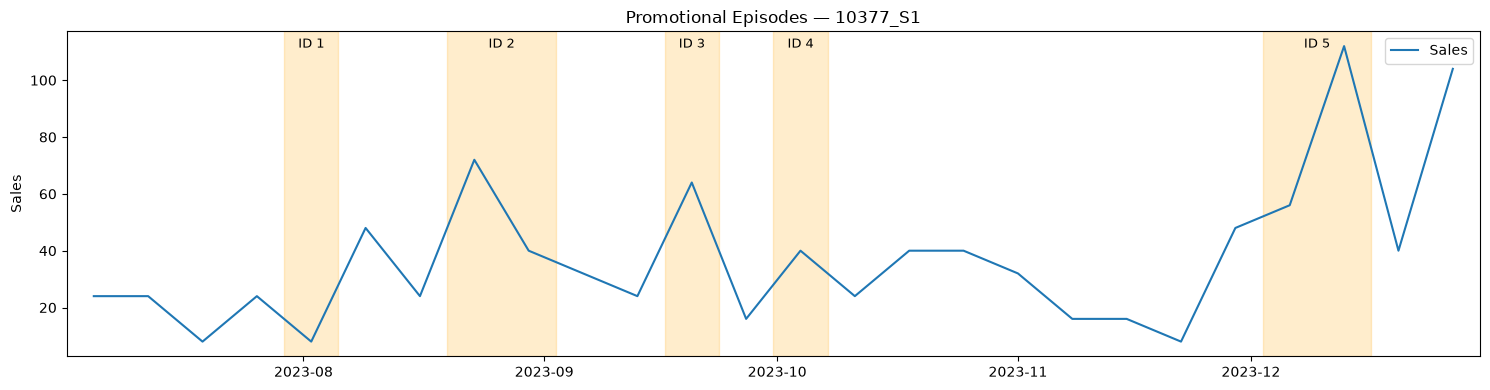

In [4]:
# Select a product with several promotional episodes
# Find products with different promotion durations
first_26 = hist.groupby("unique_id").head(26)

episode_lengths = (
    first_26.dropna(subset=["episode"])
    .groupby(["unique_id", "episode"])
    .size()
)

# Select a product with at least 3 episodes of different lengths
summary = episode_lengths.groupby("unique_id").agg(
    n_episodes="size",
    different_lengths="nunique",
    max_length="max"
)

sku = '10377_S1'

product = first_26[first_26.unique_id == sku]

product_episodes = episodes[
    (episodes.unique_id == sku) &
    (episodes.start <= product.ds.max()) &
    (episodes.end >= product.ds.min())
]
fig, ax = plt.subplots(figsize=(15, 4))

ax.plot(product.ds, product.y, label="Sales")

for _, event in product_episodes.iterrows():
    start = event.start - pd.Timedelta(days=3.5)
    end = event.end + pd.Timedelta(days=3.5)

    ax.axvspan(start, end, color="orange", alpha=0.2)

    ax.text(
        start + (end - start) / 2,
        0.95,
        f"ID {int(event.episode)}",
        transform=ax.get_xaxis_transform(),
        ha="center",
        fontsize=9
    )

ax.set_xlim(
    product.ds.min() - pd.Timedelta(days=3.5),
    product.ds.max() + pd.Timedelta(days=3.5)
)
ax.set_title(f"Promotional Episodes — {sku}")
ax.set_ylabel("Sales")
ax.legend()
plt.tight_layout()
plt.show()

In [5]:
y_lookup = hist.set_index(["unique_id", "ds"]).y

rows = []
for e in isolated.itertuples():
    weeks = pd.date_range(e.start - pd.Timedelta(weeks=8), e.end + pd.Timedelta(weeks=6), freq=FREQ)
    y = y_lookup.reindex(pd.MultiIndex.from_product([[e.unique_id], weeks])).to_numpy()
    base = y[:8].mean()
    if np.isnan(y).any() or base <= 0:
        continue
    t = np.arange(-8, len(weeks) - 8)
    rows.append(pd.DataFrame({"event": e.Index, "t_start": t, "t_end": t - (e.length - 1), "ratio": y / base, "length": e.length}))
events = pd.concat(rows)
print(f"{events.event.nunique():,} events used")

758 events used


Sales relative to the pre-promotion baseline, by week since the episode started and by week since it ended. The line is the median across events; the band is the interquartile range.

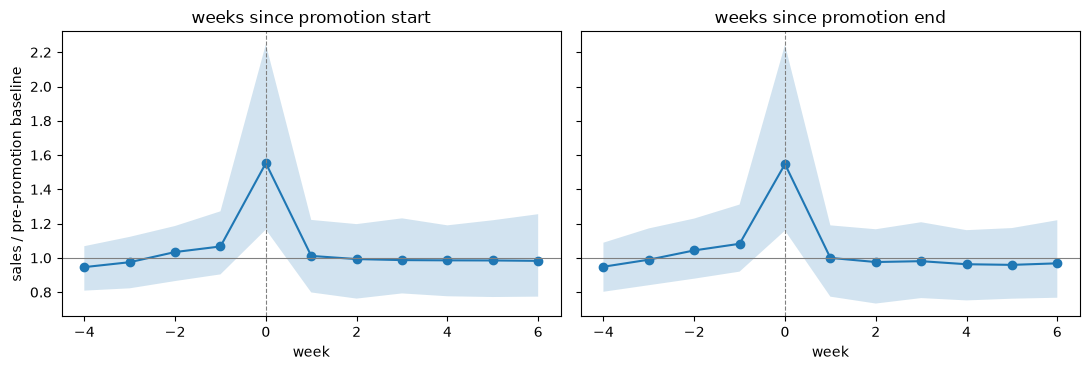

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, col, title in [(axes[0], "t_start", "weeks since promotion start"), (axes[1], "t_end", "weeks since promotion end")]:
    q = events[events[col].between(-4, 6)].groupby(col).ratio.quantile([0.25, 0.5, 0.75]).unstack()
    ax.plot(q.index, q[0.5], marker="o")
    ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.2)
    ax.axhline(1, color="grey", lw=0.8)
    ax.axvline(0, color="grey", lw=0.8, ls="--")
    ax.set(title=title, xlabel="week")
axes[0].set_ylabel("sales / pre-promotion baseline")
plt.tight_layout()

In [7]:
# Keep only promotional weeks for 1, 2 and 3-week events
during = events[
    (events.length.isin([1, 2, 3])) &
    (events.t_start >= 0) &
    (events.t_start < events.length)
].copy()

during["promo_week"] = during.t_start + 1
during["lift_pct"] = (during.ratio - 1) * 100

lift = during.groupby(["length", "promo_week"]).agg(
    median_lift=("lift_pct", "median"),
    mean_lift=("lift_pct", "mean"),
    n_events=("event", "nunique")
)

lift.round(1)

median_lift  mean_lift  n_events
length promo_week                                  
1      1                  57.4      108.2       696
2      1                 294.1      407.8         7
       2                 147.2      440.1         7
3      1                 -33.8      -33.8         2
       2                 -45.5      -45.5         2
       3                 -40.4      -40.4         2

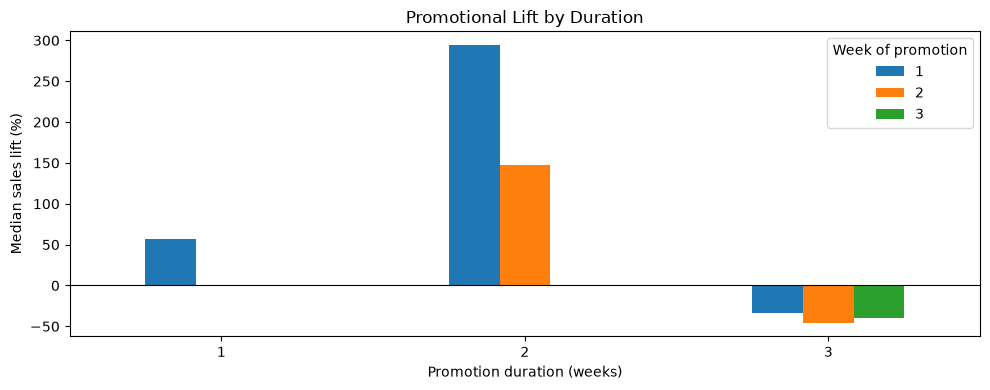

In [8]:
ax = lift["median_lift"].unstack().plot(
    kind="bar",
    figsize=(10, 4),
    rot=0
)

ax.set_title("Promotional Lift by Duration")
ax.set_xlabel("Promotion duration (weeks)")
ax.set_ylabel("Median sales lift (%)")
ax.legend(title="Week of promotion")
ax.axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()

In [9]:
during.groupby("length").event.nunique()

length
1    696
2      7
3      2
Name: event, dtype: int64

### Key Findings

- **1-week promotions:** Meaningful sales lift (~57%).
- **2-week promotions:** Strong initial lift (~294%), declining in week two (~148%).
- **3-week promotions:** Negative lift throughout, suggesting potential data quality issues or differences in product mix.
- Promotional duration and weeks into promotion may be useful forecasting features.

## Spike Adjustment

**Objective:** Remove promotional spikes from sales history to avoid inflating baseline forecasts.

### Approach

1. Replace promotional sales with the average of non-promo weeks from the previous 8 weeks.
2. Calculate historical promotional uplift (capped at 0.5–5x).
3. Train LightGBM on adjusted sales (`y_adj`).
4. Reapply uplift to future promotional weeks.

### Model Configurations

- **lgbm_adj_future:** Forecast baseline demand and reapply uplift.
- **lgbm_adj_calendar_future:** Also include promotional calendar features to capture post-promotion effects.

**Fallback:** Use portfolio uplift for products with fewer than 3 promotional weeks.

All calculations use information available at the forecast cutoff.

In [10]:
def adjust_spikes(train):
    """Return y_adj and a per-series uplift, from data up to the cutoff only."""
    train = train.sort_values(["unique_id", "ds"]).reset_index(drop=True)
    non_promo = train.y.where(train.promo == 0)
    baseline = non_promo.groupby(train.unique_id).transform(lambda s: s.shift(1).rolling(8, min_periods=1).mean())
    baseline = baseline.groupby(train.unique_id).ffill().fillna(train.y)
    train["y_adj"] = train.y.where(train.promo == 0, baseline)

    promo_weeks = train[train.promo == 1].assign(baseline=baseline[train.promo == 1])
    totals = promo_weeks.groupby("unique_id").agg(y=("y", "sum"), baseline=("baseline", "sum"), n=("y", "size"))
    portfolio = totals.y.sum() / totals.baseline.sum()
    uplift = (totals.y / totals.baseline).clip(0.5, 5).where(totals.n >= 3, portfolio)
    return train, uplift.reindex(train.unique_id.unique()).fillna(portfolio)

In [11]:
calendar_cols = ["promo_lag1", "promo_lag2", "promo_freq_13", "weeks_since_promo"]
calendar = promo_features(flags)      # the plan: flags for every week, history and forecast weeks alike
forecasts = []

for cutoff in ALL_CUTOFFS:
    history = actuals[actuals.ds <= cutoff]
    train, uplift = adjust_spikes(history.merge(flags, on=["unique_id", "ds"]))
    adjusted = (train[["unique_id", "ds", "y_adj"]].rename(columns={"y_adj": "y"})
                .merge(attributes, on="unique_id").astype({col: "category" for col in CATEGORICAL}))
    future = in_horizon(calendar, cutoff)

    # baseline demand: the adjusted target with the features of lgbm_categorical
    mlf_adj = MLForecast(
        models={"lgbm_adj_future": lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    mlf_adj.fit(adjusted, static_features=CATEGORICAL)
    base_forecast = mlf_adj.predict(H)

    # the same with promotion-calendar features from the plan, in the training frame and in X_df
    mlf_adj_calendar = MLForecast(
        models={"lgbm_adj_calendar_future": lgb.LGBMRegressor(**LGB_PARAMS)},
        freq=FREQ, lags=LAGS, lag_transforms=LAG_TRANSFORMS, date_features=DATE_FEATURES,
        target_transforms=[LocalStandardScaler()], num_threads=1,
    )
    mlf_adj_calendar.fit(adjusted.merge(calendar[["unique_id", "ds"] + calendar_cols], on=["unique_id", "ds"]), static_features=CATEGORICAL)
    calendar_forecast = mlf_adj_calendar.predict(H, X_df=future[["unique_id", "ds"] + calendar_cols])

    for name, base in [("lgbm_adj_future", base_forecast), ("lgbm_adj_calendar_future", calendar_forecast)]:
        out = base.merge(future[["unique_id", "ds", "promo"]], on=["unique_id", "ds"])
        out[name] = out[name] * np.where(out.promo == 1, out.unique_id.map(uplift), 1)
        forecasts.append(to_long(out[["unique_id", "ds", name]], cutoff, "03b_promotion_spikes", "future_drivers"))

forecasts = pd.concat(forecasts)

## Results

Against the notebook 03 models with the same setup and no spike adjustment: `lgbm_categorical` (no drivers) and `lgbm_future_promo_calendar` (the promotion plan and its calendar features). Rows every model forecasts; development origins first, then the final window (exploratory).

In [12]:
reference = load_forecasts(["03_exogenous"])
reference = reference[reference.model.isin(["lgbm_categorical", "lgbm_future_promo", "lgbm_future_promo_calendar"])]
columns = ["model", "information", "wape", "bias", "mean_rmsse", "median_rmsse", "apc", "apc_median"]
combined = pd.concat([reference, forecasts])

leaderboard(combined, actuals, scope="dev")[columns].round(3)

,model,information,wape,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_categorical,Sales history and calendar only,0.423,0.102,1.851,0.891,0.157,0.154
1,lgbm_adj_future,Full future-driver visibility,0.337,0.016,1.700,0.797,0.131,0.146
2,lgbm_adj_calendar_future,Full future-driver visibility,0.337,0.017,1.697,0.797,0.132,0.147
3,lgbm_future_promo_calendar,Full future-driver visibility,0.347,0.057,1.711,0.790,0.141,0.154
4,lgbm_future_promo,Full future-driver visibility,0.369,0.093,1.743,0.817,0.130,0.142


In [13]:
leaderboard(combined, actuals, scope="test")[columns].round(3)

,model,information,wape,bias,mean_rmsse,median_rmsse,apc,apc_median
0,lgbm_categorical,Sales history and calendar only,0.400,0.105,1.270,0.703,0.115,0.099
1,lgbm_future_promo_calendar,Full future-driver visibility,0.314,0.052,1.180,0.601,0.091,0.092
2,lgbm_adj_future,Full future-driver visibility,0.326,0.015,1.216,0.633,0.103,0.094
3,lgbm_adj_calendar_future,Full future-driver visibility,0.326,0.016,1.217,0.620,0.095,0.093
4,lgbm_future_promo,Full future-driver visibility,0.339,0.073,1.212,0.632,0.090,0.086


### Promotion and non-promotion weeks

Target weeks split by whether the item was on promotion that week (used only to slice the results). 

Bias shows whether the spike is under- or over-forecast.

In [14]:
rows = combined[combined.cutoff.isin(DEV_CUTOFFS)].merge(flags.rename(columns={"promo": "target_promo"}), on=["unique_id", "ds"])
score(rows, actuals, by=["target_promo"], rmsse=False).pivot(index="model", columns="target_promo", values=["wape", "bias"]).round(3)

wape          bias       
target_promo                    0      1      0      1
model                                                 
lgbm_adj_calendar_future    0.333  0.340  0.050 -0.014
lgbm_adj_future             0.333  0.340  0.048 -0.014
lgbm_categorical            0.516  0.338  0.330 -0.107
lgbm_future_promo           0.402  0.340  0.153  0.038
lgbm_future_promo_calendar  0.364  0.333  0.099  0.019

- Base + lift helps the base weeks but not as accurate in promo weeks

### Reading the results of this workbook

- Isolated promotions lift sales by a median of 55% in the last promotion week. Sales are back at the baseline the week after (median 1.00, then 0.98), so there is little sign of a post-promotion dip.
- With the same plan, spike adjustment is better on development: WAPE 0.337 for both adjusted models against 0.347 for `lgbm_future_promo_calendar`, with a bias near zero (+0.016 against +0.057). The final window reverses it: 0.326 against 0.314.
- The gain is in non-promotion weeks (0.333 against 0.364), where spikes no longer inflate the lags. Promotion weeks are about the same (0.340 against 0.333).
- The calendar features add nothing on top of the adjustment (0.337 either way).
- Both use the promotion plan only. The chosen plan model of notebook 03, which also knows the discount and prices, is better still (0.311 on development).

In [15]:
save_forecasts(forecasts, "03b_promotion_spikes")